# Projet 3 — Classification d'espèces de fleurs (Daisy / Rose / Tulip)
## Notebook 2 : Modélisation, entraînement et évaluation de 3 modèles

Comparaison de **k-NN**, **classifieur linéaire Softmax** et **CNN** sur les mêmes jeux de données
(`data/flowers_cleaned.npz`, produit par le notebook 1).

| Section | Contenu |
|---|---|
| 0 | Imports, chargement des données, fonctions utilitaires |
| B | Modèle 1 : k-NN (K ∈ {1,3,5,7,9}, distances L1 et L2) |
| C | Modèle 2 : classifieur linéaire Softmax |
| D | Modèle 3 : CNN simple |
| E | Résultats : tableau comparatif, matrices de confusion, courbes, prédictions |
| F | Analyse : réponses aux 8 questions du cahier des charges |

**Règle d'or :** les hyperparamètres (K, métrique, nombre d'époques) sont choisis **uniquement avec le jeu de validation**.
Le jeu de test n'est utilisé qu'une seule fois, à la fin, pour l'évaluation finale de chaque modèle.

## Section 0 — Installation, imports et chargement des données

In [ ]:
# À décommenter sur Google Colab / environnement neuf
# !pip install -q tensorflow scikit-learn matplotlib seaborn pandas

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

SEED = 42
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

DATA_PATH = "data/flowers_cleaned.npz"
d = np.load(DATA_PATH)
X_train, y_train = d["X_train"], d["y_train"]
X_val,   y_val   = d["X_val"],   d["y_val"]
X_test,  y_test  = d["X_test"],  d["y_test"]
CLASS_NAMES = [str(c) for c in d["class_names"]]
N_CLASSES = len(CLASS_NAMES)

print("Classes :", CLASS_NAMES)
print("Train :", X_train.shape, "| Val :", X_val.shape, "| Test :", X_test.shape)
print("Valeurs pixels :", X_train.min(), "→", X_train.max(), "| dtype :", X_train.dtype)
assert X_train.shape[1:] == (32, 32, 3) and len(X_train) == 540 and len(X_val) == 180 and len(X_test) == 180

I0000 00:00:1794015269.965165  148998 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794015269.966133  148998 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794015270.020838  148998 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794015271.658240  148998 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

Classes : ['Daisy', 'Rose', 'Tulip']
Train : (540, 32, 32, 3) | Val : (180, 32, 32, 3) | Test : (180, 32, 32, 3)
Valeurs pixels : 0.0 → 1.0 | dtype : float32


In [2]:
# ---------- Fonctions utilitaires communes aux trois modèles ----------
def compute_metrics(y_true, y_pred):
    # Accuracy + Precision / Recall / F1 en moyenne macro (toutes les classes pèsent pareil)
    return {
        "Accuracy":          accuracy_score(y_true, y_pred),
        "Precision (macro)": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall (macro)":    recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1-score (macro)":  f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

def plot_history(history, title, fname):
    # Courbes Training / Validation : Accuracy et Loss
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)
    best = int(np.argmin(h["val_loss"])) + 1
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    axes[0].plot(epochs, h["accuracy"], label="Train accuracy", lw=2)
    axes[0].plot(epochs, h["val_accuracy"], label="Validation accuracy", lw=2)
    axes[0].axvline(best, color="gray", ls="--", label=f"Meilleure époque ({best})")
    axes[0].set(title="Accuracy", xlabel="Époque", ylabel="Accuracy"); axes[0].legend()
    axes[1].plot(epochs, h["loss"], label="Train loss", lw=2)
    axes[1].plot(epochs, h["val_loss"], label="Validation loss", lw=2)
    axes[1].axvline(best, color="gray", ls="--", label=f"Meilleure époque ({best})")
    axes[1].set(title="Loss (cross-entropy)", xlabel="Époque", ylabel="Loss"); axes[1].legend()
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()

def show_predictions(name, y_pred, proba, fname, n=3):
    # n prédictions correctes (les plus confiantes) + n erreurs « significatives »
    # (les erreurs où le modèle était le plus sûr de lui)
    conf = proba.max(axis=1)
    ok  = np.where(y_pred == y_test)[0]
    bad = np.where(y_pred != y_test)[0]
    ok_idx  = ok[np.argsort(-conf[ok])][:n]
    bad_idx = bad[np.argsort(-conf[bad])][:n]
    fig, axes = plt.subplots(2, n, figsize=(3.2 * n, 7))
    for row, (idxs, ttl, col) in enumerate([(ok_idx, "Correct", "green"), (bad_idx, "Erreur", "red")]):
        for j in range(n):
            ax = axes[row, j]; ax.axis("off")
            if j < len(idxs):
                i = idxs[j]
                ax.imshow(X_test[i])
                ax.set_title(f"{ttl}\nRéel : {CLASS_NAMES[y_test[i]]}\nPrédit : {CLASS_NAMES[y_pred[i]]} ({conf[i]:.0%})",
                             color=col, fontsize=10)
    plt.suptitle(f"{name} — 3 prédictions correctes (haut) et 3 erreurs significatives (bas)", fontsize=12)
    plt.tight_layout()
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()
    return bad_idx

# Stockage des résultats de chaque modèle
RES, PRED, PROBA = {}, {}, {}
HIST = {}

---
# B — Modèle 1 : k-Nearest Neighbors (k-NN)

Chaque image 32 × 32 × 3 est **aplatie en un vecteur de 3072 valeurs**. Pour classer une image, on cherche les
`K` images d'entraînement les plus proches (au sens d'une distance) et on prend le vote majoritaire.

- **Distance L1 (Manhattan)** : $d_1(a,b)=\sum_i |a_i-b_i|$
- **Distance L2 (Euclidienne)** : $d_2(a,b)=\sqrt{\sum_i (a_i-b_i)^2}$

On teste **K ∈ {1, 3, 5, 7, 9}** × **{L1, L2}** = 10 configurations.
Le k-NN n'a pas d'entraînement : « fit » = mémoriser le jeu d'entraînement.

> **Règle :** K et la métrique sont choisis **uniquement sur le jeu de validation**.

In [3]:
# Aplatissement : (N, 32, 32, 3) -> (N, 3072)
Xtr_flat = X_train.reshape(len(X_train), -1)
Xva_flat = X_val.reshape(len(X_val), -1)
Xte_flat = X_test.reshape(len(X_test), -1)
print("Vecteurs aplatis :", Xtr_flat.shape)

K_VALUES = [1, 3, 5, 7, 9]
METRICS  = {"L1 (Manhattan)": "manhattan", "L2 (Euclidienne)": "euclidean"}

rows = []
for mname, metric in METRICS.items():
    for k in K_VALUES:
        knn = KNeighborsClassifier(n_neighbors=k, metric=metric, algorithm="brute")
        knn.fit(Xtr_flat, y_train)                       # entraînement = mémorisation
        val_acc = accuracy_score(y_val, knn.predict(Xva_flat))   # sélection sur VALIDATION uniquement
        rows.append({"Métrique": mname, "K": k, "Val accuracy": val_acc})

knn_grid = pd.DataFrame(rows)
display(knn_grid.pivot(index="K", columns="Métrique", values="Val accuracy").style.format("{:.4f}")
        .highlight_max(axis=None, color="lightgreen"))

Vecteurs aplatis : (540, 3072)


Métrique,L1 (Manhattan),L2 (Euclidienne)
K,,
1,0.3889,0.3944
3,0.4389,0.4389
5,0.4778,0.4222
7,0.4611,0.4167
9,0.4722,0.4222


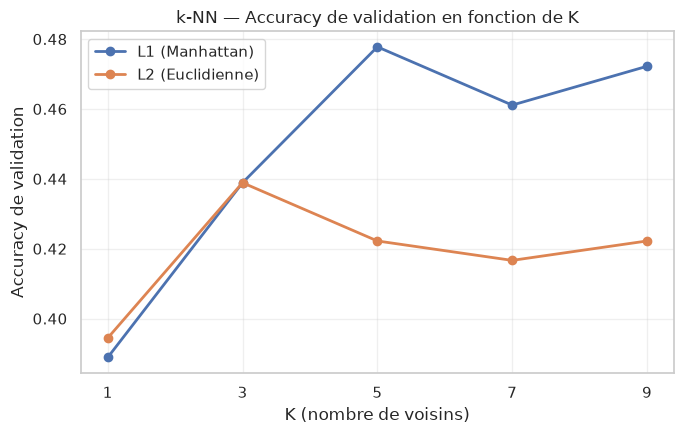

Meilleure configuration (validation) : K = 5, distance = L1 (Manhattan), val accuracy = 0.4778


In [4]:
# Courbe de validation : accuracy en fonction de K pour L1 et L2
plt.figure(figsize=(7, 4.5))
for mname in METRICS:
    sub = knn_grid[knn_grid["Métrique"] == mname]
    plt.plot(sub["K"], sub["Val accuracy"], marker="o", lw=2, label=mname)
plt.xticks(K_VALUES)
plt.xlabel("K (nombre de voisins)"); plt.ylabel("Accuracy de validation")
plt.title("k-NN — Accuracy de validation en fonction de K")
plt.legend(); plt.grid(True, alpha=.3)
plt.tight_layout(); plt.savefig("figures/04_knn_validation_K.png", dpi=150, bbox_inches="tight"); plt.show()

# Meilleure configuration d'après la validation (égalité : on garde la première, K le plus petit)
best_row = knn_grid.loc[knn_grid["Val accuracy"].idxmax()]
BEST_K, BEST_METRIC_NAME = int(best_row["K"]), best_row["Métrique"]
print(f"Meilleure configuration (validation) : K = {BEST_K}, distance = {BEST_METRIC_NAME}, "
      f"val accuracy = {best_row['Val accuracy']:.4f}")

In [5]:
# Modèle final : meilleure config, entraîné sur le TRAIN, évalué UNE SEULE FOIS sur le TEST
knn_best = KNeighborsClassifier(n_neighbors=BEST_K, metric=METRICS[BEST_METRIC_NAME], algorithm="brute")
knn_best.fit(Xtr_flat, y_train)
PRED["k-NN"]  = knn_best.predict(Xte_flat)
PROBA["k-NN"] = knn_best.predict_proba(Xte_flat)     # proportion de voisins votant pour chaque classe
RES["k-NN"]   = compute_metrics(y_test, PRED["k-NN"])
print(pd.Series(RES["k-NN"]).round(4))
print()
print(classification_report(y_test, PRED["k-NN"], target_names=CLASS_NAMES, digits=3))

Accuracy             0.4556
Precision (macro)    0.4552
Recall (macro)       0.4556
F1-score (macro)     0.4264
dtype: float64

              precision    recall  f1-score   support

       Daisy      0.458     0.633     0.531        60
        Rose      0.453     0.567     0.504        60
       Tulip      0.455     0.167     0.244        60

    accuracy                          0.456       180
   macro avg      0.455     0.456     0.426       180
weighted avg      0.455     0.456     0.426       180



---
# C — Modèle 2 : classifieur linéaire Softmax

**Architecture (aucune couche cachée) :** `Input 32×32×3 → Flatten (3072) → Dense(3) + Softmax`

### Rôle de chaque élément

- **x** : l'image aplatie, un vecteur de 3072 valeurs.
- **W** : matrice de poids de taille $3072 \times 3$. Chaque colonne est un « gabarit » (template) pour une classe :
  elle indique quels pixels (et quelles couleurs) augmentent ou diminuent le score de cette classe.
- **b** : vecteur de biais de taille 3, un décalage propre à chaque classe (indépendant de l'image).
- **$Wx+b$** : les **scores** (logits) $z = W^\top x + b$, un score réel par classe. Opération purement **linéaire**,
  d'où le nom de classifieur linéaire.
- **Softmax** : transforme les scores en probabilités, $p_k = \dfrac{e^{z_k}}{\sum_j e^{z_j}}$. Les $p_k$ sont positifs et somment à 1.
  Elle sert aussi à définir la perte d'entraînement (cross-entropy $L = -\log p_{\text{classe réelle}}$).
- **argmax** : au moment de la prédiction, la classe prédite est $\hat y = \arg\max_k p_k$ (identique à $\arg\max_k z_k$,
  car Softmax est strictement croissante).

Entraînement : Adam, perte `sparse_categorical_crossentropy`. Le nombre d'époques est limité par un
*early stopping* surveillant la **perte de validation** (on restaure les poids de la meilleure époque).

In [6]:
keras.utils.set_random_seed(SEED)

linear = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Flatten(),                           # 3072 valeurs
    layers.Dense(N_CLASSES, activation="softmax", name="linear_softmax"),   # W (3072x3) + b (3)
], name="classifieur_lineaire_softmax")

linear.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
               loss="sparse_categorical_crossentropy", metrics=["accuracy"])
linear.summary()

E0000 00:00:1794015276.619146  148998 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



Model: "classifieur_lineaire_softmax"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ linear_softmax (Dense)          │ (None, 3)              │         9,219 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,219 (36.01 KB)

 Trainable params: 9,219 (36.01 KB)

 Non-trainable params: 0 (0.00 B)

Entraînement terminé en 4.3s — 21 époques (poids de la meilleure époque restaurés)


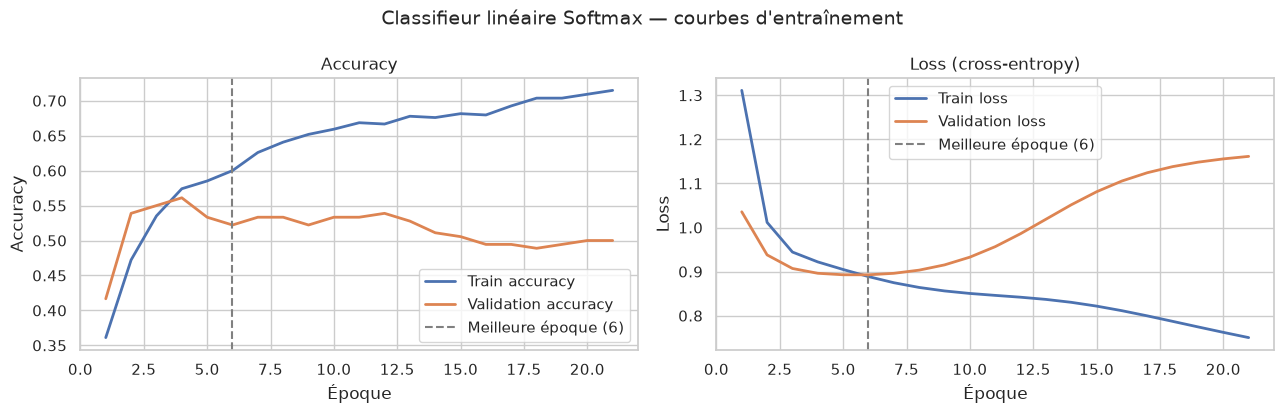

In [7]:
early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)

t0 = time.time()
HIST["Linéaire Softmax"] = linear.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=150, batch_size=32, callbacks=[early], verbose=0)
print(f"Entraînement terminé en {time.time()-t0:.1f}s — {len(HIST['Linéaire Softmax'].history['loss'])} époques "
      f"(poids de la meilleure époque restaurés)")
plot_history(HIST["Linéaire Softmax"], "Classifieur linéaire Softmax — courbes d'entraînement",
             "figures/05_linear_courbes.png")

In [8]:
proba = linear.predict(X_test, verbose=0)
PROBA["Linéaire Softmax"] = proba
PRED["Linéaire Softmax"]  = proba.argmax(axis=1)            # argmax des probabilités
RES["Linéaire Softmax"]   = compute_metrics(y_test, PRED["Linéaire Softmax"])
print(pd.Series(RES["Linéaire Softmax"]).round(4))
print()
print(classification_report(y_test, PRED["Linéaire Softmax"], target_names=CLASS_NAMES, digits=3))

Accuracy             0.5278
Precision (macro)    0.5615
Recall (macro)       0.5278
F1-score (macro)     0.5091
dtype: float64

              precision    recall  f1-score   support

       Daisy      0.542     0.650     0.591        60
        Rose      0.667     0.267     0.381        60
       Tulip      0.476     0.667     0.556        60

    accuracy                          0.528       180
   macro avg      0.562     0.528     0.509       180
weighted avg      0.562     0.528     0.509       180



W : (3072, 3) | b : (3,) | b = [-0.008  0.004  0.005]


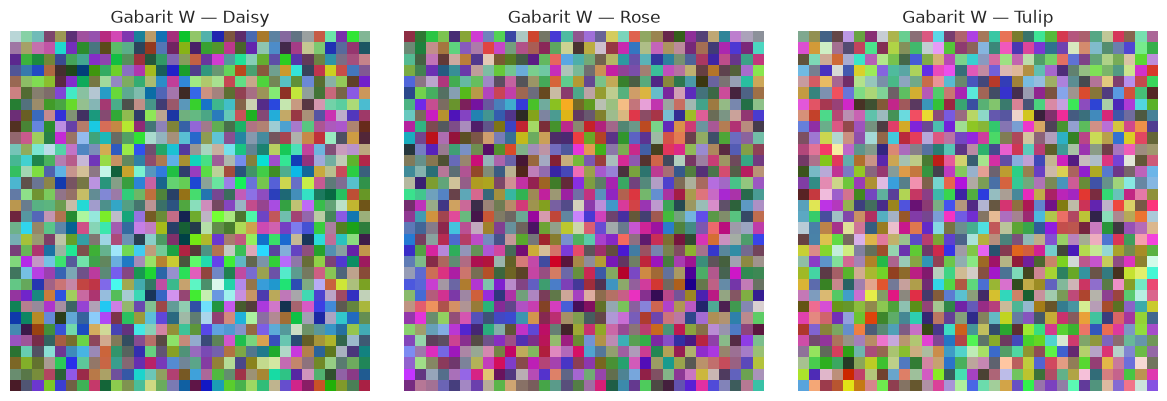


Image test #0 (classe réelle : Daisy)
Scores Wx+b : [ 0.596 -0.6   -0.714]
Softmax     : [0.636 0.192 0.172] | somme = 1.0
argmax      : Daisy


In [9]:
# Visualisation de W : un « gabarit » 32x32x3 par classe (colonnes de W remises en forme d'image)
W, b = linear.get_layer("linear_softmax").get_weights()
print("W :", W.shape, "| b :", b.shape, "| b =", np.round(b, 3))

fig, axes = plt.subplots(1, N_CLASSES, figsize=(4 * N_CLASSES, 4))
for c in range(N_CLASSES):
    w = W[:, c].reshape(32, 32, 3)
    w = (w - w.min()) / (w.max() - w.min() + 1e-9)          # remise à l'échelle [0,1] pour l'affichage
    axes[c].imshow(w); axes[c].axis("off"); axes[c].set_title(f"Gabarit W — {CLASS_NAMES[c]}")
plt.tight_layout(); plt.savefig("figures/06_linear_poids_W.png", dpi=150, bbox_inches="tight"); plt.show()

# Exemple concret de Wx + b -> softmax -> argmax sur une image de test
i = 0
z = X_test[i].reshape(-1) @ W + b
p = np.exp(z - z.max()); p /= p.sum()
print(f"\nImage test #{i} (classe réelle : {CLASS_NAMES[y_test[i]]})")
print("Scores Wx+b :", np.round(z, 3))
print("Softmax     :", np.round(p, 3), "| somme =", p.sum().round(3))
print("argmax      :", CLASS_NAMES[int(p.argmax())])

---
# D — Modèle 3 : Convolutional Neural Network (CNN) simple

```
Conv2D(32, 3×3) + ReLU → MaxPooling2D → Conv2D(64, 3×3) + ReLU → MaxPooling2D
→ Flatten → Dense(64) + ReLU → Dense(3) + Softmax
```
Architecture volontairement simple, conforme au cahier des charges (pas de dropout, pas d'augmentation de données).
Même protocole que le modèle linéaire : Adam, cross-entropy, early stopping sur la perte de validation.

In [10]:
keras.utils.set_random_seed(SEED)

cnn = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(N_CLASSES, activation="softmax"),
], name="cnn_simple")

cnn.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
            loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.summary()

Model: "cnn_simple"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,107 (652.76 KB)

 Trainable params: 167,107 (652.76 KB)

 Non-trainable params: 0 (0.00 B)

Entraînement terminé en 11.5s — 27 époques (poids de la meilleure époque restaurés)


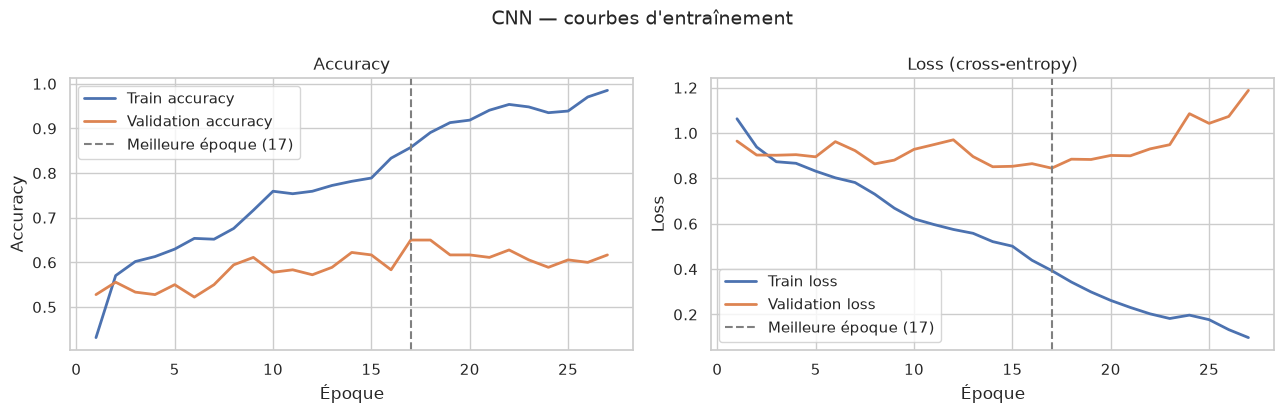

In [11]:
early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

t0 = time.time()
HIST["CNN"] = cnn.fit(X_train, y_train, validation_data=(X_val, y_val),
                      epochs=60, batch_size=32, callbacks=[early], verbose=0)
print(f"Entraînement terminé en {time.time()-t0:.1f}s — {len(HIST['CNN'].history['loss'])} époques "
      f"(poids de la meilleure époque restaurés)")
plot_history(HIST["CNN"], "CNN — courbes d'entraînement", "figures/07_cnn_courbes.png")

In [12]:
proba = cnn.predict(X_test, verbose=0)
PROBA["CNN"] = proba
PRED["CNN"]  = proba.argmax(axis=1)
RES["CNN"]   = compute_metrics(y_test, PRED["CNN"])
print(pd.Series(RES["CNN"]).round(4))
print()
print(classification_report(y_test, PRED["CNN"], target_names=CLASS_NAMES, digits=3))

Accuracy             0.6500
Precision (macro)    0.6493
Recall (macro)       0.6500
F1-score (macro)     0.6361
dtype: float64

              precision    recall  f1-score   support

       Daisy      0.685     0.833     0.752        60
        Rose      0.649     0.400     0.495        60
       Tulip      0.614     0.717     0.662        60

    accuracy                          0.650       180
   macro avg      0.649     0.650     0.636       180
weighted avg      0.649     0.650     0.636       180



---
# E — Résultats et visualisations

## E.1 Tableau comparatif final (jeu de test, mêmes données pour les 3 modèles)

,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Modèle,,,,
k-NN,0.4556,0.4552,0.4556,0.4264
Linéaire Softmax,0.5278,0.5615,0.5278,0.5091
CNN,0.6500,0.6493,0.6500,0.6361


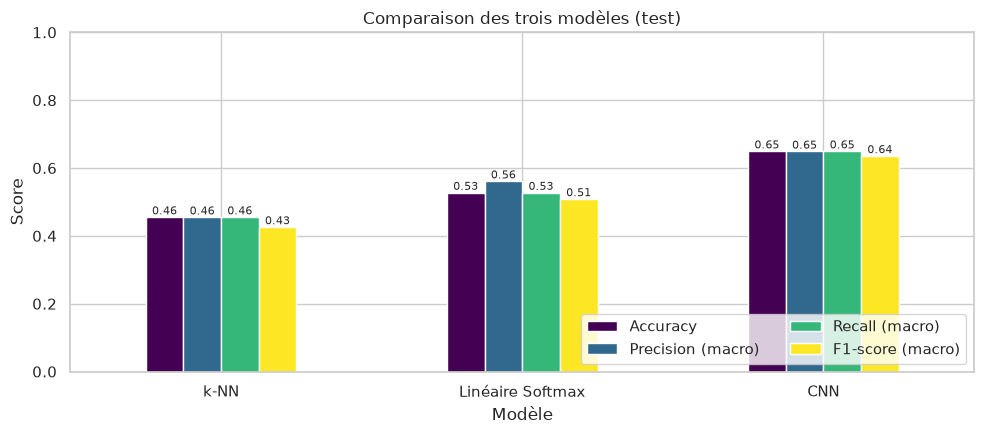

In [13]:
MODELS = ["k-NN", "Linéaire Softmax", "CNN"]
results = pd.DataFrame(RES).T.loc[MODELS]
results.index.name = "Modèle"
results.to_csv("results/tableau_comparatif.csv")

display(results.style.format("{:.4f}").highlight_max(axis=0, color="lightgreen")
        .set_caption("Performances sur le jeu de test (meilleure valeur par métrique en vert)"))

# Version graphique
ax = results.plot(kind="bar", figsize=(10, 4.5), rot=0, colormap="viridis", ylim=(0, 1))
ax.set_title("Comparaison des trois modèles (test)"); ax.set_ylabel("Score")
for cont in ax.containers: ax.bar_label(cont, fmt="%.2f", fontsize=8)
ax.legend(loc="lower right", ncol=2)
plt.tight_layout(); plt.savefig("figures/08_comparaison_modeles.png", dpi=150, bbox_inches="tight"); plt.show()

## E.2 Matrices de confusion (une par modèle)

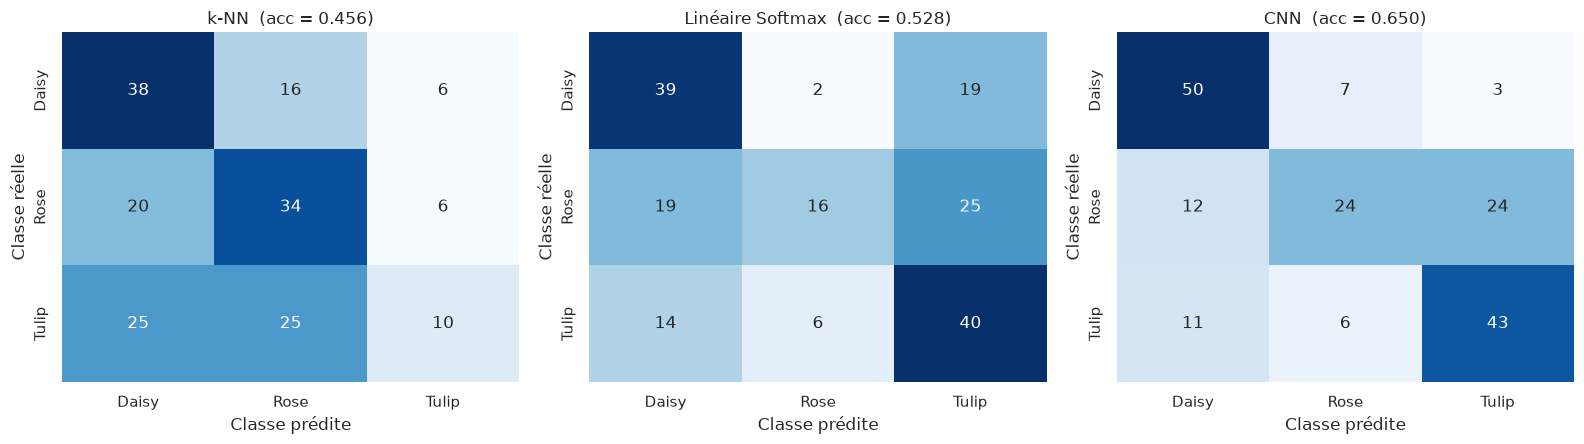

In [14]:
CMS = {m: confusion_matrix(y_test, PRED[m], labels=range(N_CLASSES)) for m in MODELS}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, m in zip(axes, MODELS):
    sns.heatmap(CMS[m], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_title(f"{m}  (acc = {RES[m]['Accuracy']:.3f})")
    ax.set_xlabel("Classe prédite"); ax.set_ylabel("Classe réelle")
plt.tight_layout(); plt.savefig("figures/09_matrices_confusion.png", dpi=150, bbox_inches="tight"); plt.show()

## E.3 Courbes d'entraînement

- **k-NN** : courbe Accuracy de validation en fonction de K (L1 et L2) → figure `04_knn_validation_K.png`, affichée dans la section B.
- **Linéaire Softmax** et **CNN** : courbes Training/Validation Accuracy et Loss affichées ci-dessous côte à côte.

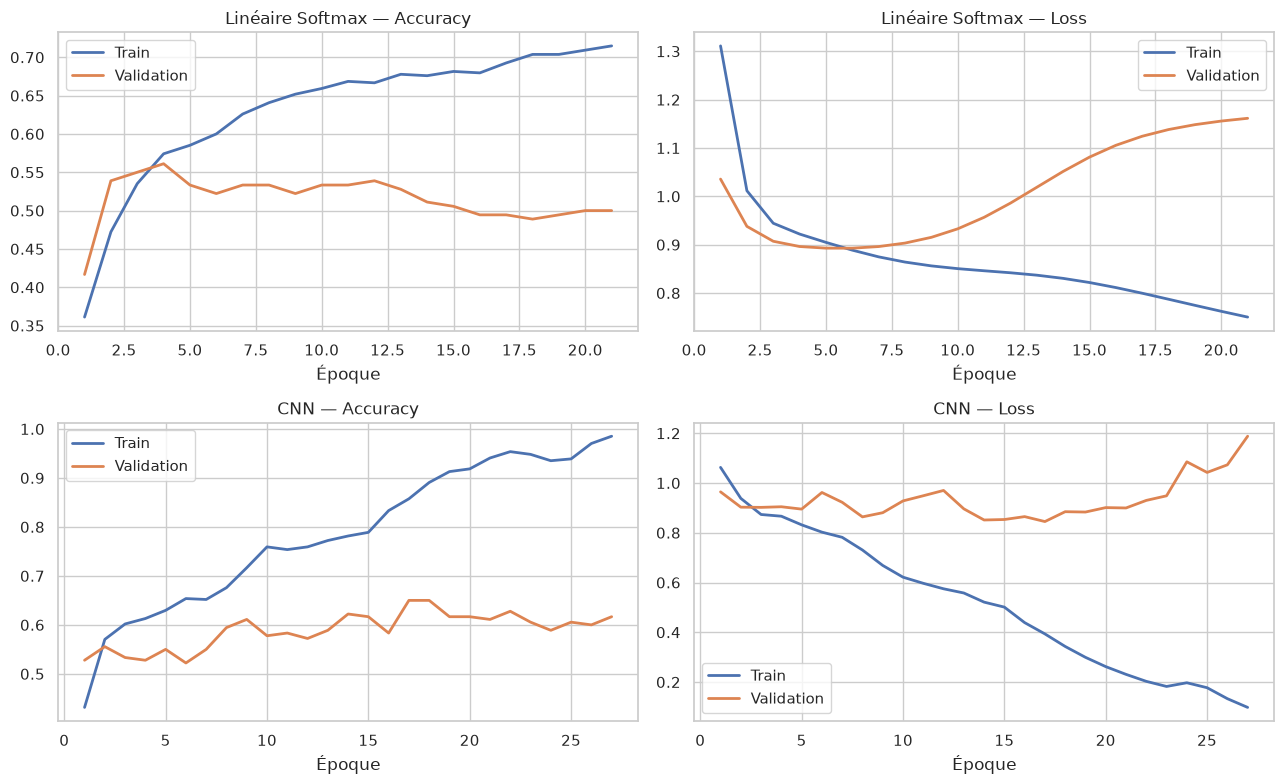

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for r, m in enumerate(["Linéaire Softmax", "CNN"]):
    h = HIST[m].history; ep = range(1, len(h["loss"]) + 1)
    axes[r, 0].plot(ep, h["accuracy"], label="Train", lw=2); axes[r, 0].plot(ep, h["val_accuracy"], label="Validation", lw=2)
    axes[r, 0].set(title=f"{m} — Accuracy", xlabel="Époque"); axes[r, 0].legend()
    axes[r, 1].plot(ep, h["loss"], label="Train", lw=2); axes[r, 1].plot(ep, h["val_loss"], label="Validation", lw=2)
    axes[r, 1].set(title=f"{m} — Loss", xlabel="Époque"); axes[r, 1].legend()
plt.tight_layout(); plt.savefig("figures/10_courbes_comparees.png", dpi=150, bbox_inches="tight"); plt.show()

## E.4 Prédictions correctes et erreurs significatives (3 + 3 par modèle)

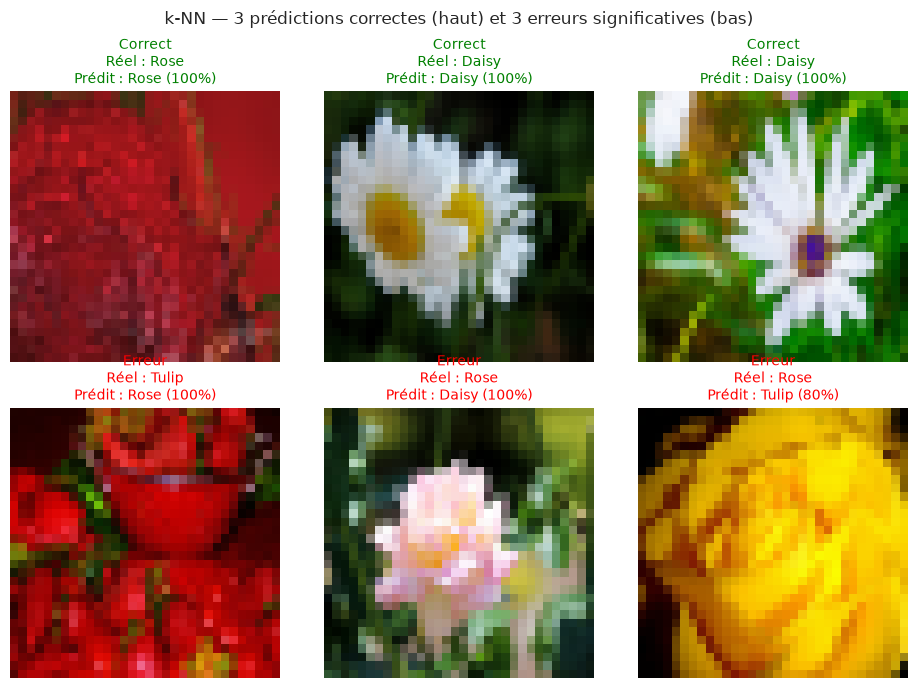

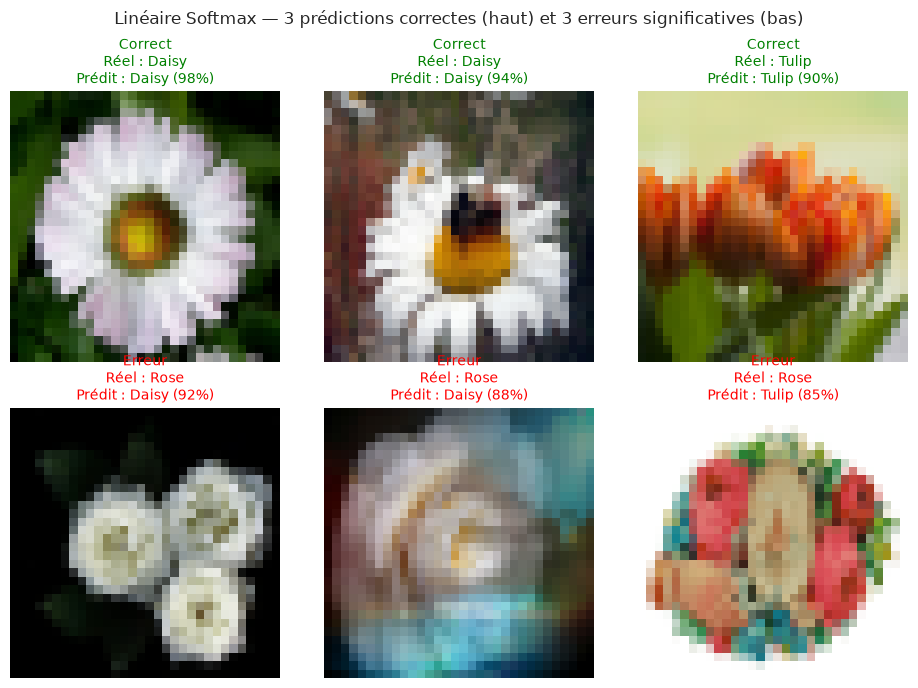

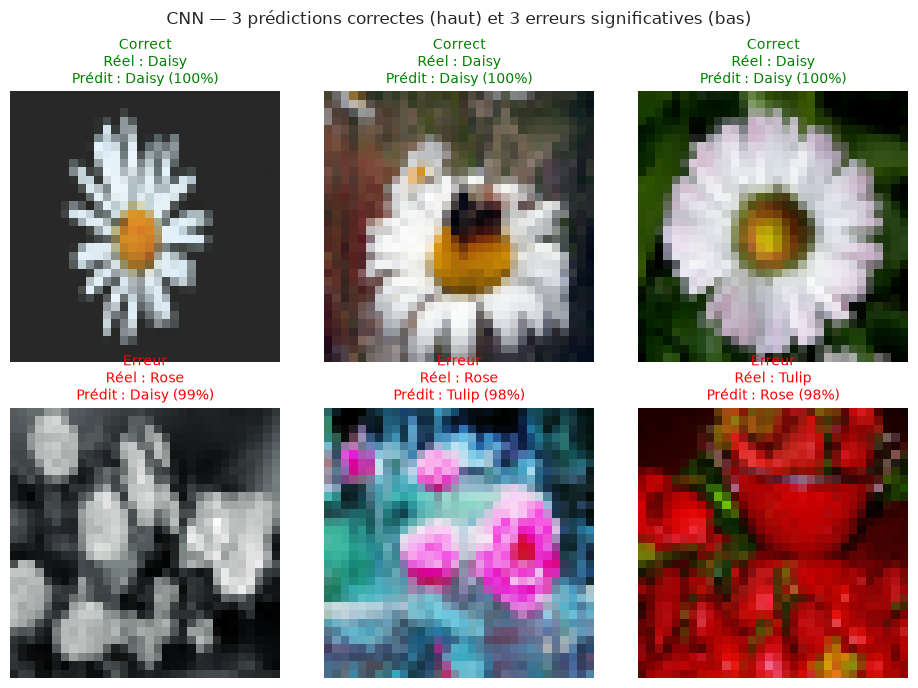

In [16]:
BAD = {}
for i, m in enumerate(MODELS):
    BAD[m] = show_predictions(m, PRED[m], PROBA[m], f"figures/11_predictions_{i}.png", n=3)

## E.5 Discussion des erreurs : classe réelle, classe prédite et explication visuelle

In [17]:
# Tableau des erreurs « significatives » (les plus confiantes) de chaque modèle
rows = []
for m in MODELS:
    for i in BAD[m]:
        rows.append({"Modèle": m, "Index test": int(i),
                     "Classe réelle": CLASS_NAMES[y_test[i]],
                     "Classe prédite": CLASS_NAMES[PRED[m][i]],
                     "Confiance": f"{PROBA[m][i].max():.0%}",
                     "Couleur moyenne RGB": tuple(np.round(X_test[i].reshape(-1, 3).mean(0) * 255).astype(int))})
err_table = pd.DataFrame(rows)
display(err_table)

# Couleur moyenne par classe : aide à juger si une confusion est due à la couleur
mean_rgb = pd.DataFrame({CLASS_NAMES[c]: (X_train[y_train == c].reshape(-1, 3).mean(0) * 255).round(0)
                         for c in range(N_CLASSES)}, index=["R", "G", "B"]).T
print("Couleur moyenne (RGB, 0–255) par classe sur le train :")
display(mean_rgb)

,Modèle,Index test,Classe réelle,Classe prédite,Confiance,Couleur moyenne RGB
0,k-NN,103,Tulip,Rose,100%,"(129, 19, 9)"
1,k-NN,82,Rose,Daisy,100%,"(104, 109, 79)"
2,k-NN,65,Rose,Tulip,80%,"(192, 141, 1)"
3,Linéaire Softmax,152,Rose,Daisy,92%,"(63, 66, 60)"
4,Linéaire Softmax,50,Rose,Daisy,88%,"(100, 111, 109)"
5,Linéaire Softmax,33,Rose,Tulip,85%,"(200, 179, 163)"
6,CNN,22,Rose,Daisy,99%,"(90, 94, 95)"
7,CNN,24,Rose,Tulip,98%,"(104, 118, 151)"
8,CNN,103,Tulip,Rose,98%,"(129, 19, 9)"


Couleur moyenne (RGB, 0–255) par classe sur le train :


,R,G,B
Daisy,109.0,111.0,86.0
Rose,127.0,95.0,81.0
Tulip,123.0,102.0,76.0


Mal classées par les 3 modèles : 31 | ratées par k-NN et Softmax mais bien classées par le CNN : 19


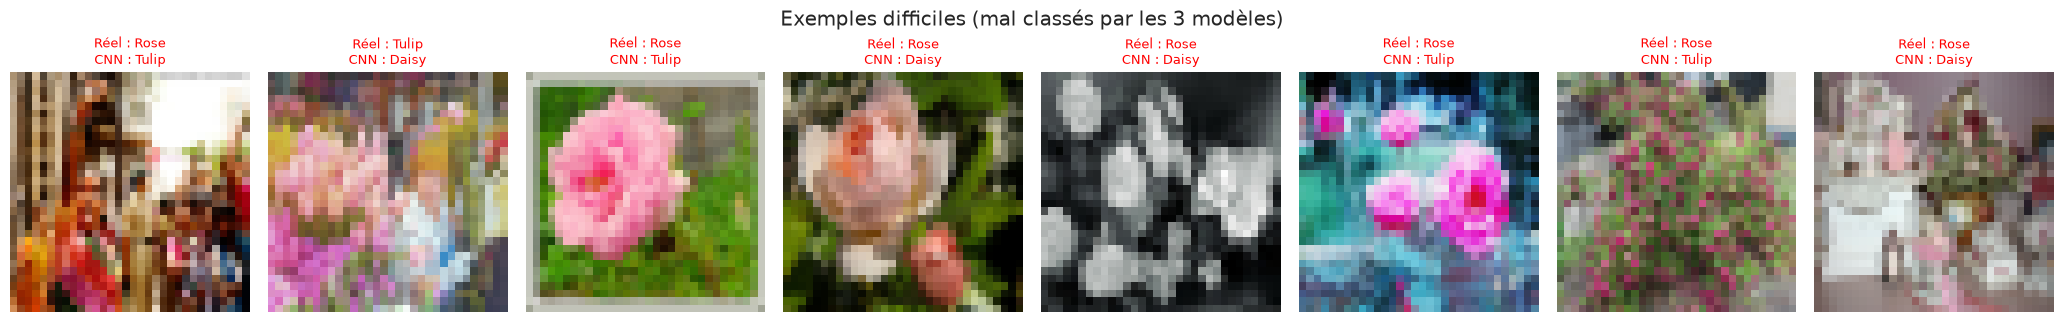

In [18]:
# Images difficiles : mal classées par LES TROIS modèles
wrong = {m: PRED[m] != y_test for m in MODELS}
all_wrong  = np.where(wrong["k-NN"] & wrong["Linéaire Softmax"] & wrong["CNN"])[0]
only_cnn_ok = np.where(wrong["k-NN"] & wrong["Linéaire Softmax"] & ~wrong["CNN"])[0]
print(f"Mal classées par les 3 modèles : {len(all_wrong)} | ratées par k-NN et Softmax mais bien classées par le CNN : {len(only_cnn_ok)}")

show = all_wrong[:8]
if len(show):
    fig, axes = plt.subplots(1, len(show), figsize=(2.6 * len(show), 3.4), squeeze=False)
    for ax, i in zip(axes[0], show):
        ax.imshow(X_test[i]); ax.axis("off")
        ax.set_title(f"Réel : {CLASS_NAMES[y_test[i]]}\nCNN : {CLASS_NAMES[PRED['CNN'][i]]}", fontsize=9, color="red")
    plt.suptitle("Exemples difficiles (mal classés par les 3 modèles)")
    plt.tight_layout(); plt.savefig("figures/12_exemples_difficiles.png", dpi=150, bbox_inches="tight"); plt.show()

**Comment lire les erreurs ci-dessus.** Pour chaque erreur, regarder : (1) la classe réelle et la classe prédite ;
(2) la **couleur dominante** (une Rose et une Tulip rouges/roses se ressemblent beaucoup à 32×32) ;
(3) le **fond** (herbe, feuillage, ciel : un fond vert dominant ne discrimine pas les classes) ;
(4) la **forme** (pétales blancs rayonnants autour d'un cœur jaune = Daisy ; corolle en coupe fermée = Tulip ;
pétales superposés en spirale = Rose) ; (5) le **cadrage** (fleur petite, partielle, de profil ou entourée d'autres fleurs).
Compléter vos commentaires visuels dans le rapport à partir de ces images.

---
# F — Analyse attendue

Les cellules de code ci-dessous calculent automatiquement les éléments chiffrés qui répondent aux 8 questions.
Les paragraphes d'interprétation sont à **confirmer / compléter avec vos propres résultats** (ils dépendent des valeurs obtenues).

### Q1 — Quel modèle obtient les meilleures performances et sur quelles métriques ?

In [19]:
best_per_metric = results.idxmax()
for m_, mod in best_per_metric.items():
    print(f"{m_:18s} → {mod:18s} ({results.loc[mod, m_]:.4f})")
print()
ranking = results["F1-score (macro)"].sort_values(ascending=False)
print("Classement par F1 macro :", " > ".join(f"{k} ({v:.3f})" for k, v in ranking.items()))

Accuracy           → CNN                (0.6500)
Precision (macro)  → CNN                (0.6493)
Recall (macro)     → CNN                (0.6500)
F1-score (macro)   → CNN                (0.6361)

Classement par F1 macro : CNN (0.636) > Linéaire Softmax (0.509) > k-NN (0.426)


### Q2 — Les trois modèles se trompent-ils sur les mêmes classes ?

In [20]:
# Recall par classe (= 1 - taux d'erreur de la classe) pour chaque modèle
per_class = pd.DataFrame({m: recall_score(y_test, PRED[m], average=None, labels=range(N_CLASSES), zero_division=0)
                          for m in MODELS}, index=CLASS_NAMES)
per_class.index.name = "Classe"
display(per_class.style.format("{:.3f}").background_gradient(cmap="RdYlGn", vmin=0.3, vmax=1))

hardest = {m: CLASS_NAMES[int(per_class[m].values.argmin())] for m in MODELS}
print("Classe la plus difficile par modèle :", hardest)

# Recouvrement des erreurs au niveau des images
n_err = {m: int(wrong[m].sum()) for m in MODELS}
print("\nNombre d'erreurs (sur 180) :", n_err)
print("Erreurs communes k-NN ∩ Softmax :", int((wrong["k-NN"] & wrong["Linéaire Softmax"]).sum()))
print("Erreurs communes k-NN ∩ CNN     :", int((wrong["k-NN"] & wrong["CNN"]).sum()))
print("Erreurs communes Softmax ∩ CNN  :", int((wrong["Linéaire Softmax"] & wrong["CNN"]).sum()))
print("Erreurs communes aux 3 modèles  :", len(all_wrong))

,k-NN,Linéaire Softmax,CNN
Classe,,,
Daisy,0.633,0.650,0.833
Rose,0.567,0.267,0.400
Tulip,0.167,0.667,0.717


Classe la plus difficile par modèle : {'k-NN': 'Tulip', 'Linéaire Softmax': 'Rose', 'CNN': 'Rose'}

Nombre d'erreurs (sur 180) : {'k-NN': 98, 'Linéaire Softmax': 85, 'CNN': 63}
Erreurs communes k-NN ∩ Softmax : 50
Erreurs communes k-NN ∩ CNN     : 40
Erreurs communes Softmax ∩ CNN  : 50
Erreurs communes aux 3 modèles  : 31


### Q3 — Que révèle la matrice de confusion ?

In [21]:
def top_confusion(cm):
    # paire (réel -> prédit) hors diagonale la plus fréquente + paire non ordonnée la plus confondue
    off = cm.copy(); np.fill_diagonal(off, 0)
    i, j = np.unravel_index(off.argmax(), off.shape)
    sym = off + off.T
    a, b_ = np.unravel_index(np.triu(sym).argmax(), sym.shape)
    return (CLASS_NAMES[i], CLASS_NAMES[j], int(off[i, j])), (CLASS_NAMES[a], CLASS_NAMES[b_], int(sym[a, b_]))

for m in MODELS:
    (r, p, n), (a, b_, s) = top_confusion(CMS[m])
    print(f"{m:17s} | confusion dirigée la + fréquente : {r} pris pour {p} ({n}x) | "
          f"paire la + confondue : {a} <-> {b_} ({s} erreurs au total)")

k-NN              | confusion dirigée la + fréquente : Tulip pris pour Daisy (25x) | paire la + confondue : Daisy <-> Rose (36 erreurs au total)
Linéaire Softmax  | confusion dirigée la + fréquente : Rose pris pour Tulip (25x) | paire la + confondue : Daisy <-> Tulip (33 erreurs au total)
CNN               | confusion dirigée la + fréquente : Rose pris pour Tulip (24x) | paire la + confondue : Rose <-> Tulip (30 erreurs au total)


**Interprétation à compléter.** Les erreurs se concentrent hors de la diagonale sur une ou deux paires de classes.
Rose et Tulip (fleurs colorées, souvent rouges/roses, corolle fermée, même feuillage vert) sont attendues
comme la paire la plus confondue, alors que la Daisy (pétales blancs, cœur jaune) est plus facile à isoler par la couleur.
Vérifiez ce point avec la paire affichée ci-dessus et les matrices de confusion de la section E.2.

### Q4 — Le k-NN semble-t-il limité par la distance directe entre pixels ?

**Éléments de réponse.** Le k-NN compare deux images pixel par pixel (L1 ou L2). Cette distance mesure surtout la
**ressemblance globale des couleurs et de la luminosité**, pas le contenu sémantique : deux photos de la même fleur
légèrement décalées, zoomées ou avec un fond différent peuvent être très éloignées, tandis que deux fleurs d'espèces
différentes sur un fond vert similaire peuvent être proches. En plus, en dimension 3072 les distances se concentrent
(« malédiction de la dimension ») et tous les voisins deviennent presque équidistants. Avec seulement 540 images
d'entraînement, la densité de l'espace est faible. Si votre k-NN est nettement en dessous du CNN, c'est le signe de cette limite.

In [22]:
gap_knn = results.loc["CNN", "Accuracy"] - results.loc["k-NN", "Accuracy"]
print(f"Écart d'accuracy CNN − k-NN : {gap_knn:+.3f}")
print(f"Meilleure distance sur validation : {BEST_METRIC_NAME}, K = {BEST_K}")
print("Valeur de l'accuracy aléatoire (3 classes) : 0.333")

Écart d'accuracy CNN − k-NN : +0.194
Meilleure distance sur validation : L1 (Manhattan), K = 5
Valeur de l'accuracy aléatoire (3 classes) : 0.333


### Q5 — Quelles limites du classifieur linéaire apparaissent dans les résultats ?

**Éléments de réponse.** Le modèle ne peut apprendre qu'**un seul gabarit global par classe** (colonnes de W, visualisées
plus haut) : les scores sont une somme pondérée de pixels, sans notion de position relative, de forme ni de contexte.
Il ne peut donc exploiter que la **couleur/luminosité par zone** et échoue dès que la fleur n'est pas au même endroit
ou que le fond change. La frontière de décision est un hyperplan, incapable de séparer des classes dont les distributions
se recouvrent (Rose vs Tulip). Il n'a pas de capacité d'invariance à la translation. Observez sur les gabarits W : ils ressemblent
à des « taches de couleur moyenne », ce qui confirme qu'il apprend surtout des couleurs.

In [23]:
print(f"Linéaire Softmax : accuracy test = {results.loc['Linéaire Softmax','Accuracy']:.3f} | "
      f"CNN : {results.loc['CNN','Accuracy']:.3f} | k-NN : {results.loc['k-NN','Accuracy']:.3f}")

Linéaire Softmax : accuracy test = 0.528 | CNN : 0.650 | k-NN : 0.456


### Q6 — Qu'apporte le CNN grâce à l'apprentissage de motifs spatiaux locaux ?

**Éléments de réponse.** Les filtres 3×3 sont appliqués à **chaque position** de l'image (poids partagés) : le CNN détecte
des motifs locaux (bords, textures, courbures de pétales, centre jaune) **où qu'ils soient** (équivariance à la translation),
et le max-pooling apporte une tolérance aux petits décalages. Les couches successives composent des motifs simples en
motifs plus complexes (bords → pétales → fleur). Il utilise donc la **forme et la texture** en plus de la couleur, ce qui aide
à séparer des classes proches en couleur (Rose/Tulip). Il a aussi **beaucoup moins de paramètres** qu'un Dense sur 3072 entrées
pour une même capacité de représentation. Comparez avec le nombre de paramètres affichés dans les `summary()`.

In [24]:
print(f"Paramètres — Linéaire : {linear.count_params():,} | CNN : {cnn.count_params():,}")
print(f"Gain du CNN sur le Softmax linéaire : Accuracy {results.loc['CNN','Accuracy']-results.loc['Linéaire Softmax','Accuracy']:+.3f}, "
      f"F1 macro {results.loc['CNN','F1-score (macro)']-results.loc['Linéaire Softmax','F1-score (macro)']:+.3f}")

Paramètres — Linéaire : 9,219 | CNN : 167,107
Gain du CNN sur le Softmax linéaire : Accuracy +0.122, F1 macro +0.127


### Q7 — Observe-t-on du surapprentissage ou du sous-apprentissage sur les courbes ?

In [25]:
def diagnose(m):
    h = HIST[m].history
    b = int(np.argmin(h["val_loss"]))              # meilleure époque (poids restaurés)
    tr_acc, va_acc = h["accuracy"][b], h["val_accuracy"][b]
    tr_last, va_last = h["accuracy"][-1], h["val_accuracy"][-1]
    gap_best, gap_last = tr_acc - va_acc, tr_last - va_last
    loss_up = h["val_loss"][-1] - min(h["val_loss"])
    if max(tr_last, va_last) < 0.60:
        verdict = "SOUS-APPRENTISSAGE probable (accuracy faible même sur le train)"
    elif gap_last > 0.15 and loss_up > 0.05:
        verdict = "SURAPPRENTISSAGE net (train >> val et val_loss qui remonte)"
    elif gap_last > 0.08 or loss_up > 0.10:
        verdict = "début de surapprentissage (écart train-val modéré ou val_loss qui remonte)"
    else:
        verdict = "pas de surapprentissage marqué (courbes proches)"
    print(f"{m:17s} | meilleure époque = {b+1:3d}/{len(h['loss'])} | train acc = {tr_last:.3f} | val acc = {va_last:.3f} "
          f"| écart = {gap_last:+.3f} | remontée val_loss = {loss_up:+.3f}\n{'':17s} → {verdict}")

for m in ["Linéaire Softmax", "CNN"]:
    diagnose(m)

Linéaire Softmax  | meilleure époque =   6/21 | train acc = 0.715 | val acc = 0.500 | écart = +0.215 | remontée val_loss = +0.269
                  → SURAPPRENTISSAGE net (train >> val et val_loss qui remonte)
CNN               | meilleure époque =  17/27 | train acc = 0.985 | val acc = 0.617 | écart = +0.369 | remontée val_loss = +0.343
                  → SURAPPRENTISSAGE net (train >> val et val_loss qui remonte)


**Lecture des courbes.** *Surapprentissage* : l'accuracy d'entraînement continue de monter (la loss descend) alors que la
validation stagne ou se dégrade (la loss de validation remonte) : le modèle mémorise les 540 images. C'est fréquent pour le
CNN sur un si petit jeu de données, d'où l'early stopping. *Sous-apprentissage* : les deux courbes restent basses et proches,
signe d'un modèle trop peu expressif, ce qui peut arriver au classifieur linéaire. Pour le k-NN : K = 1 est très sensible au bruit
(variance élevée), les grandes valeurs de K lissent trop (biais) : voir la courbe de validation en fonction de K.

### Q8 — Quels exemples difficiles permettent d'expliquer les performances obtenues ?

In [26]:
# Pour les erreurs communes aux 3 modèles : quelles confusions et quelle couleur moyenne ?
if len(all_wrong):
    hard = pd.DataFrame({
        "Index test": all_wrong,
        "Réel": [CLASS_NAMES[y_test[i]] for i in all_wrong],
        "Prédit (CNN)": [CLASS_NAMES[PRED["CNN"][i]] for i in all_wrong],
        "Confiance CNN": [f"{PROBA['CNN'][i].max():.0%}" for i in all_wrong],
    })
    display(hard)
    print("Confusions les plus fréquentes parmi ces cas :")
    print(hard.groupby(["Réel", "Prédit (CNN)"]).size().sort_values(ascending=False).head(3).to_string())
else:
    print("Aucune image n'est mal classée par les trois modèles à la fois.")

,Index test,Réel,Prédit (CNN),Confiance CNN
0,2,Rose,Tulip,72%
1,3,Tulip,Daisy,56%
2,6,Rose,Tulip,75%
3,12,Rose,Daisy,66%
4,22,Rose,Daisy,99%
5,24,Rose,Tulip,98%
6,26,Rose,Tulip,45%
7,29,Rose,Daisy,79%
8,34,Rose,Daisy,42%
9,35,Daisy,Tulip,51%


Confusions les plus fréquentes parmi ces cas :
Réel   Prédit (CNN)
Rose   Tulip           10
Tulip  Daisy            8
Rose   Daisy            6


**Éléments de réponse.** Les exemples difficiles typiques : fleur très petite ou partielle dans le cadre, fond dominant (herbe,
feuillage, pot), plusieurs fleurs sur la même image, flou, fleur de profil ou en bouton, Rose et Tulip de même couleur (rouge, rose, jaune).
À 32 × 32, de nombreux détails discriminants (nombre de pétales, forme de la corolle) disparaissent et il ne reste que la couleur
dominante. Si ces images sont mal classées même par le CNN, la limite vient de l'information disponible (résolution + petit jeu de données)
plutôt que du modèle.

---
# Conclusion et sauvegarde des résultats

Cette section répond à l'objectif du projet : **comparer trois familles de classifieurs sur un même problème réel**
avec exactement les mêmes données (540 / 180 / 180 images), le même protocole et les mêmes métriques.

In [27]:
# Sauvegarde des résultats et des modèles (livrable : « notebook avec résultats sauvegardés »)
results.round(4).to_csv("results/tableau_comparatif.csv")
knn_grid.to_csv("results/knn_grille_validation.csv", index=False)
linear.save("results/linear_softmax.keras")
cnn.save("results/cnn.keras")
np.savez("results/predictions_test.npz", y_test=y_test, **{m.replace(" ", "_"): PRED[m] for m in MODELS})

print("Tableau final (à reporter dans le rapport et la soutenance) :")
display(results.round(4))
print("\nFichiers dans results/ :", sorted(os.listdir("results")))
print("Figures dans figures/  :", sorted(os.listdir("figures")))

Tableau final (à reporter dans le rapport et la soutenance) :


,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Modèle,,,,
k-NN,0.4556,0.4552,0.4556,0.4264
Linéaire Softmax,0.5278,0.5615,0.5278,0.5091
CNN,0.6500,0.6493,0.6500,0.6361



Fichiers dans results/ : ['cnn.keras', 'knn_grille_validation.csv', 'linear_softmax.keras', 'predictions_test.npz', 'tableau_comparatif.csv']
Figures dans figures/  : ['01_exemples_classes.png', '02_distribution_donnees.png', '03_histogramme_pixels.png', '04_knn_validation_K.png', '05_linear_courbes.png', '06_linear_poids_W.png', '07_cnn_courbes.png', '08_comparaison_modeles.png', '09_matrices_confusion.png', '10_courbes_comparees.png', '11_predictions_0.png', '11_predictions_1.png', '11_predictions_2.png', '12_exemples_difficiles.png']
